# 04 · Feature engineering — AccessGuard AI

**Qué hacemos:** convertir 6 códigos categóricos anónimos en variables numéricas que un modelo pueda aprovechar.
Cada idea es una **hipótesis que se mide**, no una columna que "suena bien".

| Familia | Variables | Idea |
|---|---|---|
| Frecuencias | `freq__*` | ¿Qué tan común es este recurso / gerente / rol? (log(1+conteo)) |
| Interacciones | `RESOURCE_x_MGR_ID`, `ROLE_TITLE_x_ROLE_DEPTNAME`, … | La combinación importa más que cada pieza por separado |
| Agregaciones por grupo | `nuniq__*`, `share__*` | Nº de recursos distintos por gerente / departamento / rol |
| Target encoding | `te__*` | Tasa suavizada de aprobación por categoría, **calculada fuera de pliegue** |

**Reglas que se respetan (CLAUDE.md):** la validación es **por gerente** (`StratifiedGroupKFold`), todo lo que aprende de los datos
vive en `IAMFeatureBuilder` (`src/accessguard/engineering.py`) y la **reserva (`holdout`) y `test.csv` no se usan para decidir nada**.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config.settings import PROCESSED_DIR, REPORTS_DIR, SEED, TARGET, GROUP_COL
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)   # se crean si no existen
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Datos limpios de la fase anterior (`03_preprocesamiento`)

`train_clean.csv` es el entrenamiento; `holdout_clean.csv` es la reserva cerrada (gerentes que el entrenamiento nunca ve);
`test_clean.csv` es el `test.csv` de la competencia (sin etiqueta). Las columnas de `selected_features.json` son las que sobrevivieron al EDA.

In [2]:
import json
train = pd.read_csv(PROCESSED_DIR / "train_clean.csv")
holdout = pd.read_csv(PROCESSED_DIR / "holdout_clean.csv")
test = pd.read_csv(PROCESSED_DIR / "test_clean.csv")
sel = json.loads((PROCESSED_DIR / "selected_features.json").read_text(encoding="utf-8"))
BASE = sel["model_features"]
print("variables base:", BASE)
print(f"train {train.shape} · holdout {holdout.shape} (CERRADA) · test {test.shape}")
print(f"tasa de aprobación en train: {train[TARGET].mean():.3%}  |  gerentes en train: {train[GROUP_COL].nunique():,}")
print("gerentes de test vistos en train:", f"{test[GROUP_COL].isin(train[GROUP_COL]).mean():.1%}",
      "| gerentes del holdout vistos en train:", f"{holdout[GROUP_COL].isin(train[GROUP_COL]).mean():.1%}")

variables base: ['RESOURCE', 'MGR_ID', 'ROLE_ROLLUP_2', 'ROLE_DEPTNAME', 'ROLE_TITLE', 'ROLE_FAMILY_DESC']
train (26215, 7) · holdout (6554, 7) (CERRADA) · test (58921, 7)
tasa de aprobación en train: 94.209%  |  gerentes en train: 3,360
gerentes de test vistos en train: 77.8% | gerentes del holdout vistos en train: 0.0%


> **Por qué importa la última línea:** el holdout se partió por gerente, así que sus gerentes son *nuevos* (0 % vistos); en `test.csv` casi 8 de cada 10
> filas sí tienen gerente conocido. Las variables basadas en el gerente (frecuencia, target encoding) valen menos en la validación por gerente que en `test.csv`;
> la validación es, por diseño, **la estimación prudente**.

## 2. El transformador `IAMFeatureBuilder`

Se ajusta solo con entrenamiento y expone `fit_transform` (con target encoding **fuera de pliegue**) y `transform` (con el ajuste completo).
Vemos primero qué columnas produce:

In [3]:
from accessguard.engineering import IAMFeatureBuilder, add_interactions

y = train[TARGET].to_numpy()
X = train.drop(columns=TARGET)
fb = IAMFeatureBuilder(seed=SEED)
F_train = fb.fit_transform(X, y)
print(F_train.shape)
pd.Series({fam: [c for c in F_train.columns if c.startswith(fam + "__")] for fam in ["freq", "nuniq", "share", "te"]}).to_frame("columnas")

(26215, 29)


,columnas
freq,"[freq__RESOURCE, freq__MGR_ID, freq__ROLE_ROLL..."
nuniq,"[nuniq__RESOURCE_por_MGR_ID, nuniq__RESOURCE_p..."
share,[share__RESOURCE_en_MGR]
te,"[te__RESOURCE, te__MGR_ID, te__ROLE_ROLLUP_2, ..."


## 3. Demostración anti-fuga: por qué el target encoding va fuera de pliegue

Si codificamos cada fila con una tasa que **incluye su propia etiqueta**, la variable "ya sabe" la respuesta. Comparamos, para `RESOURCE_x_MGR_ID`
(muchas categorías con pocas filas), el AUC univariante de tres versiones — **sobre las mismas filas de entrenamiento**:

* *ingenua*: tabla ajustada con todas las filas y aplicada a esas mismas filas (con fuga);
* *fuera de pliegue (OOF)*: la que usa `IAMFeatureBuilder`;
* *gerentes nuevos (honesta)*: tabla ajustada con unos gerentes y aplicada a gerentes distintos.

In [4]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

col = "RESOURCE_x_MGR_ID"
cats = add_interactions(X)
naive = cats[col].map(fb.te_tables_[col]).fillna(fb.prior_)           # con fuga
oof = F_train[f"te__{col}"]                                           # fuera de pliegue

# validación honesta: ajustar en 4/5 de los gerentes y aplicar al 1/5 restante
honest = pd.Series(index=cats.index, dtype=float)
for tr, va in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(cats, y, groups=X[GROUP_COL]):
    tabla = fb._te_table(cats.iloc[tr], y[tr])
    honest.iloc[va] = fb._apply_te(cats.iloc[va], tabla, y[tr].mean())[f"te__{col}"].to_numpy()

pd.DataFrame({"AUC univariante": {
    "ingenua (con fuga)": roc_auc_score(y, naive),
    "fuera de pliegue (OOF)": roc_auc_score(y, oof),
    "gerentes nuevos (honesta)": roc_auc_score(y, honest)}}).round(4)

,AUC univariante
ingenua (con fuga),0.9996
fuera de pliegue (OOF),0.4993
gerentes nuevos (honesta),0.4996


**Lectura.** La versión ingenua da un AUC más alto, pero es un espejismo: se alimenta de la etiqueta que luego pretende predecir. La versión OOF
queda al nivel de la honesta (≈ 0,5: esta interacción es casi única por fila, no trae señal real) — por eso es la que se usa. El 0,9996 de la ingenua es memorización pura. Un modelo entrenado con la ingenua parecería excelente en entrenamiento y fallaría con gerentes nuevos.

## 4. ¿Qué familias de variables aportan? (ablación medida por gerente)

Mismo modelo (LightGBM con parámetros fijos), mismas 5 particiones por gerente, solo cambia el conjunto de columnas. Las variables de cada pliegue
se calculan **una vez** con `fold_matrices` (ajustadas solo con el entrenamiento de ese pliegue). Se reportan ROC-AUC y PR-AUC de la clase *denegar*.

In [5]:
from lightgbm import LGBMClassifier
from accessguard.modeling import fold_matrices, make_cv, metrics_at

cv = make_cv(5, SEED)
folds = fold_matrices(X, y, X[GROUP_COL], cv, seed=SEED)
cols = list(F_train.columns)
families = {
    "solo frecuencias de las 6 columnas base": [c for c in cols if c.startswith("freq__") and "_x_" not in c],
    "+ interacciones (frecuencia)": [c for c in cols if c.startswith("freq__")],
    "+ agregaciones por grupo": [c for c in cols if c.startswith(("freq__", "nuniq__", "share__"))],
    "solo target encoding (OOF)": [c for c in cols if c.startswith("te__")],
    "TODAS": cols,
}
rows = {}
for name, subset in families.items():
    res = []
    for X_tr, y_tr, X_va, y_va, _ in folds:
        m = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=SEED, verbose=-1).fit(X_tr[subset], y_tr)
        res.append(metrics_at(y_va, m.predict_proba(X_va[subset])[:, 1]))
    r = pd.DataFrame(res)
    rows[name] = {"n_cols": len(subset), "ROC-AUC": r.roc_auc.mean(), "± ROC": r.roc_auc.std(),
                  "PR-AUC denegar": r.pr_auc_deny.mean(), "± PR": r.pr_auc_deny.std()}
ablation = pd.DataFrame(rows).T
ablation.to_csv(REPORTS_DIR / "04_features_ablacion.csv")
ablation.round(4)

,n_cols,ROC-AUC,± ROC,PR-AUC denegar,± PR
solo frecuencias de las 6 columnas base,6.0,0.6353,0.0519,0.1094,0.0209
+ interacciones (frecuencia),11.0,0.6523,0.0346,0.1300,0.0192
+ agregaciones por grupo,18.0,0.6736,0.0412,0.1466,0.0306
solo target encoding (OOF),11.0,0.7051,0.0253,0.1597,0.0318
TODAS,29.0,0.6912,0.0232,0.1539,0.0276


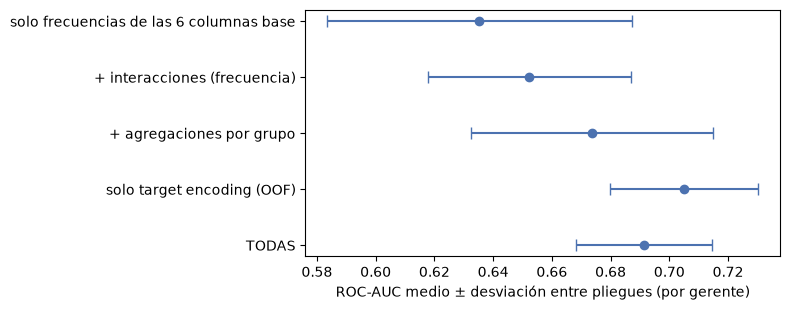

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.errorbar(ablation["ROC-AUC"], range(len(ablation)), xerr=ablation["± ROC"], fmt="o", capsize=4, color="#4c72b0")
ax.set_yticks(range(len(ablation))); ax.set_yticklabels(ablation.index); ax.invert_yaxis()
ax.set_xlabel("ROC-AUC medio ± desviación entre pliegues (por gerente)"); plt.tight_layout(); plt.show()

**Cómo leerlo:** una familia aporta si su mejora supera el ruido entre pliegues (la barra). Si dos filas se solapan, la diferencia no se distingue del azar con
estos datos. Con la validación por gerente el techo es modesto (el AUC base de la etapa 3 era ≈ 0,70): el gerente es nuevo en cada pliegue, así que las señales útiles
vienen sobre todo de *recurso* y *rol*.

## 5. Guardar los datasets transformados

* `train_features.parquet`: variables de entrenamiento (target encoding OOF) + `ACTION` + `MGR_ID` (clave de grupo, **no** es variable del modelo).
* `test_features.parquet`: `test_clean.csv` transformado con el ajuste completo de entrenamiento (+ `id`).
* `holdout_features.parquet`: la reserva transformada igual. **Se guarda pero no se mira**: se abrirá una sola vez en la etapa de validación.

> **Aviso importante.** Estos parquet sirven para inspección y para la app/inferencia. Para **medir** modelos (notebooks 05 y 06) las variables se recalculan
> dentro de cada pliegue (`fold_matrices`); usar el parquet de entrenamiento directamente en una validación cruzada filtraría información de los pliegues de validación.

In [7]:
F_test = fb.transform(test.drop(columns=["id"], errors="ignore"))
F_hold = fb.transform(holdout.drop(columns=TARGET))

train_out = F_train.assign(**{TARGET: y, GROUP_COL: X[GROUP_COL].to_numpy()})
test_out = F_test.assign(**{GROUP_COL: test[GROUP_COL].to_numpy()})
if "id" in test:
    test_out["id"] = test["id"].to_numpy()
hold_out = F_hold.assign(**{TARGET: holdout[TARGET].to_numpy(), GROUP_COL: holdout[GROUP_COL].to_numpy()})

train_out.to_parquet(PROCESSED_DIR / "train_features.parquet", index=False)
test_out.to_parquet(PROCESSED_DIR / "test_features.parquet", index=False)
hold_out.to_parquet(PROCESSED_DIR / "holdout_features.parquet", index=False)

# comprobaciones
assert list(F_train.columns) == list(F_test.columns) == list(F_hold.columns)
assert not F_train.isna().any().any() and not F_test.isna().any().any()
print("train_features:", train_out.shape, "| test_features:", test_out.shape, "| holdout_features:", hold_out.shape)
print("guardado en", PROCESSED_DIR)

train_features: (26215, 31) | test_features: (58921, 31) | holdout_features: (6554, 31)
guardado en D:\Carpetas de sistema\Escritorio\Laboratorio avanzado analitica\ab-casos-avanzados2026v2\laboratorio-avanzado-iam\Data\processed


## 6. Decisión (con lo que mostró la ablación)

* **Lo que dicen los números:** el *target encoding* OOF es la familia con más señal (ROC-AUC ≈ 0,705). Las frecuencias, interacciones y agregaciones por sí solas son más débiles
  (0,64–0,67), y al sumarlas **todas** el promedio (≈ 0,691) no mejora al del target encoding solo; la diferencia (≈ 0,014) es menor que la desviación entre pliegues (≈ 0,023–0,025), así que
  **no se distingue del ruido**. No hay evidencia de que las frecuencias y agregaciones aporten sobre el target encoding con esta validación.
* **Por qué las de gerente ayudan poco:** en la validación por gerente, el gerente es *nuevo* en cada pliegue (frecuencia 0, sin historial). Con `test.csv` (78 % de gerentes conocidos) podrían valer más, pero eso no se puede medir sin etiqueta: es un **supuesto, no un resultado**.
* **Decisión para el torneo (05):** se pasan al torneo las **29 variables** (se pidió explorar las cuatro familias y no hay evidencia de que dañen), dejando constancia de que el target encoding solo es una alternativa más simple con rendimiento equivalente.
  Si en la optimización o la validación final se confirma, se retira el resto de `IAMFeatureBuilder`.
* El target encoding **siempre** es fuera de pliegue y suavizado (`SMOOTH = 20`): una categoría con pocas filas se acerca a la media global en vez de memorizar su etiqueta.
* Función en `src/accessguard/engineering.py`; pruebas en `tests/test_engineering.py`.

**Siguiente:** `05_torneo_modelos.ipynb`.